# Streaming video overfit

Record a rolling frame stream in AsyncLLM, check replay, train a student, and compare its autonomous gate decisions and answer. The protocol uses previous/current images, a persistent thinker, a yes/no gate, and a writer.

Replay uses `torch` attention with query chunks of 64. Configure these in `SETUP`; cached reports must match. Use a fresh `RUN` directory to repeat collection and training. Figures are embedded in notebook outputs.

## A. Setup

Use the project environment with the video example dependencies. Teacher and student share the same question, frames, greedy policy, and token-count schedule. Each model stage runs in a separate process. Set `OVERFIT_RUN` to select a fresh output directory.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "python/minisgl/training/recording.py").exists()
)
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "scripts"), str(ROOT / "python")]
os.environ["PYTHONPATH"] = ":".join(
    [str(ROOT / "python"), str(ROOT / "scripts"), os.environ.get("PYTHONPATH", "")]
)
os.environ["PATH"] = str(Path(sys.executable).parent) + ":/usr/local/cuda/bin:" + os.environ["PATH"]
os.environ.setdefault("CUDA_HOME", "/usr/local/cuda")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")
os.environ["MPLBACKEND"] = "Agg"

import json
import subprocess
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from minisgl.training import Trace
from PIL import Image

from minisgl_examples.training.process import isolated
from minisgl_examples.training.video_understanding import experiment as exp


def display_figure(fig):
    # Explicit PNG, including in headless kernels using Agg.
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
        display(DisplayImage(data=buffer.getvalue()))


TEACHER = "Qwen/Qwen3.5-4B"
STUDENT = "Qwen/Qwen3.5-0.8B"
SETUP = exp.asdict(exp.Setup(replay_attention_backend="torch", replay_query_chunk_size=64))
RUN = Path(os.environ.get("OVERFIT_RUN", ROOT / "training_runs/video_understanding"))
RUN.mkdir(parents=True, exist_ok=True)
print(
    subprocess.check_output(
        ["nvidia-smi", "--query-gpu=index,name,memory.used,utilization.gpu", "--format=csv"],
        text=True,
    )
)
print("Selected GPU:", os.environ["CUDA_VISIBLE_DEVICES"])
print("Run:", RUN)
print(SETUP)


/home/mrozaeva/experiments/image-steering-overfit/repo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


index, name, memory.used [MiB], utilization.gpu [%]
0, NVIDIA H100 80GB HBM3, 79823 MiB, 100 %
1, NVIDIA H100 80GB HBM3, 5105 MiB, 64 %

Selected GPU: 1
Run: /home/mrozaeva/experiments/video-replay-refresh-20261127/training_runs/executed_notebook
{'seed': 7, 'tokens_per_frame': 16, 'writer_tokens': 96, 'max_pixels': 65536, 'kv_tokens': 8192, 'prefill_rows': 128, 'dtype': 'float16', 'replay_attention_backend': 'torch', 'replay_query_chunk_size': 64}


## B. Task and the visible stream

The pinned ProactiveVideoQA/VAD clip contains a destructive event at a building. The reference reply window is `[6, 16]` seconds. The stream samples frames at **2, 5, 12, 14 seconds**; the first frame containing the selected evidence arrives at 12 seconds. Only visual frames are provided, with no audio.

The model sees the original user question and frame timestamps. Reference answers, reply windows, filenames and event identities are kept outside inference. The source clip, annotation, dataset revision, and frame hashes are loaded from Hugging Face by `prepare.py`.

What suspicious or harmful activities, including unlawful, criminal behaviors or destructive accidents, are happening in the video?

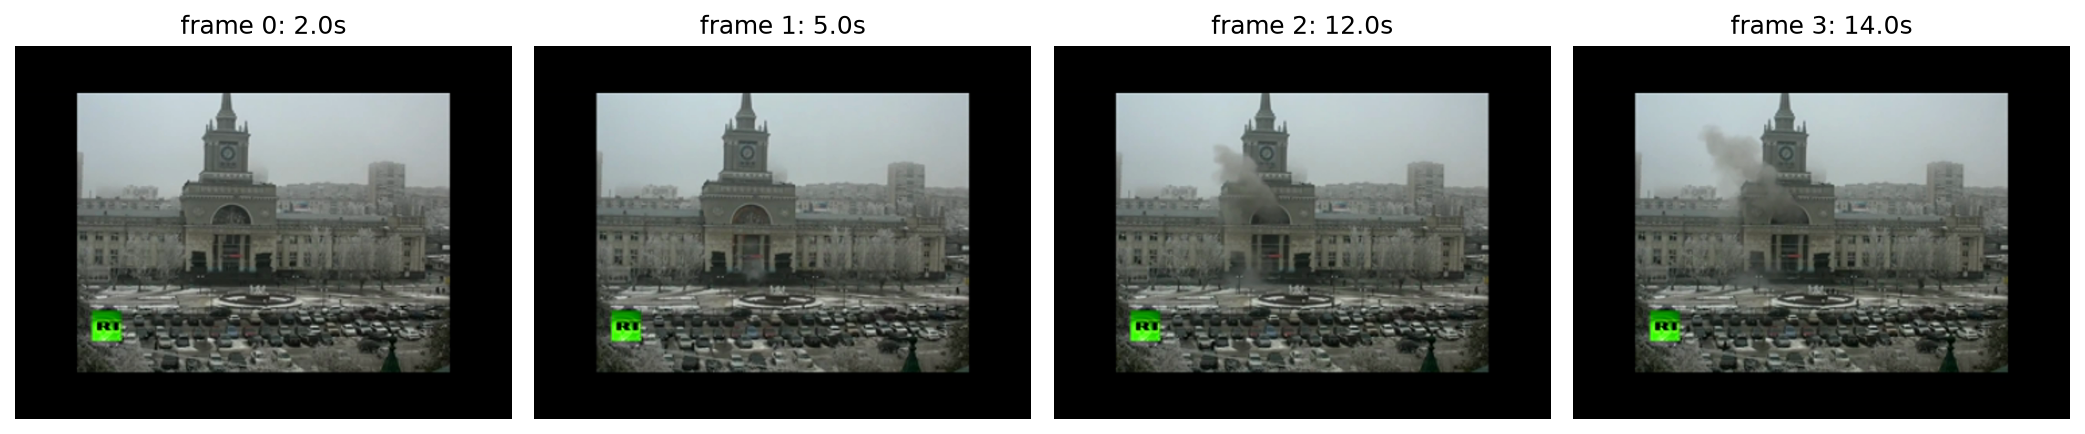

Reference: {'role': 'assistant', 'content': 'An explosion occurred in the distant building, and white smoke came out after a burst of fire.', 'related_timespan': [6.0, 15.0], 'reply_timespan': [6.0, 16.0], 'num_captions': 1}
Video SHA256: 0672b58c87ec43c15e03f5a543f1b86f81852bc34756a6eb6dabf9080b7de42c


In [2]:
task = exp.task()
display(Markdown(task["annotation"]["conversation"][0]["content"]))
fig, axes = plt.subplots(1, len(task["frames"]), figsize=(14, 3.3))
for i, (ax, frame) in enumerate(zip(axes, task["frames"], strict=True)):
    ax.imshow(Image.open(exp.frame_path(frame)))
    ax.set_title(f"frame {i}: {frame['time']:.1f}s")
    ax.axis("off")
plt.tight_layout()
display_figure(fig)
plt.close(fig)
print("Reference:", task["annotation"]["answer"][0])
print("Video SHA256:", task["video_sha256"])


## C. Real asynchronous teacher inference

Each observation is a rolling pair `(previous, current)` encoded as **two images**, matching the demo's protocol. This is not a native video tensor: current replay supports image requests with their full three-axis MRoPE metadata.

Views: thinker `[prompt, observation, thinker]`, gate `[prompt, observation, gate]`, writer `[prompt, observation, thinker, writer]`. Historical thinker KV stays intact while the observation block is replaced through recorded `free_block` / `prefill_block` calls. Every 16 generated thinker tokens a gate independently decides whether to answer. If it chooses yes, writer generates its own sentence and EOS. No teacher action schedule is supplied at evaluation.

The source frames arrive after fixed thinker-token quotas, not wall-clock delays; model-dependent gate decisions can make a run finish early or miss the event. The thinker masks end-of-turn/control tokens to keep monitoring, and the gate chooses the highest-logit one-token spelling of yes/no. Raw pre-mask logprobs are recorded.

In [3]:
def collect_once(model, name, *, control="normal"):
    path = RUN / f"{name}.json"
    if not path.exists():
        isolated(exp.collect, model, path, SETUP, control=control, log_path=RUN / f"{name}.log")
    data = exp.require_replay_options(exp.load(path), SETUP)
    assert data["model"] == str(model) and data["setup"] == SETUP
    assert data["control"] == control and data["task"] == exp.task()
    return path, data


teacher_path, teacher = collect_once(TEACHER, "teacher")
print("Teacher:", teacher["assessment"])
print("Gate sequence:", teacher["gates"])
print("Thinker:", teacher["thinker_text"])
print("Writer:", teacher["answer_text"])
assert teacher["assessment"]["behavior_reproduced"], "Teacher failed: do not train on it."


Teacher: {'reply_time': 12.0, 'in_reference_window': True, 'correct_gate_sequence': True, 'facts': {'smoke': True, 'building': True, 'explosion_or_fire': True}, 'answer_grounded': True, 'behavior_reproduced': True}
Gate sequence: [{'frame': 0, 'video_time': 2.0, 'reply': False, 'token': 2083, 'margin': -4.421875}, {'frame': 1, 'video_time': 5.0, 'reply': False, 'token': 2083, 'margin': -4.1875}, {'frame': 2, 'video_time': 12.0, 'reply': True, 'token': 9405, 'margin': 1.625}]
Thinker: The user wants me to compare two video frames to identify any suspicious or harmful activities1.  **Analyze the first frame (2.0s):** The2.  **Analyze the second frame (12.0s):**
Writer: A large plume of dark smoke is rising from the center of the building's facade, indicating a fire or explosion.


## D. Trace and event inspection

Format-v2 traces retain original pixels (not cached embeddings), grids, image token types, MRoPE positions, write positions, ordered cache views with visible lengths, and block-clearing references. Both frames of every pair are recorded in their actual arrival order. Old observations remain available to replay through historical versions, while later inference reads only the current observation.

Only model-generated thinker tokens, gate action tokens and writer tokens are supervised. Prefixes, image inputs, prompt text, and flush rows use `-100`; a global next-token shift would be wrong.

The thinker is intentionally limited to 16 tokens per observation and may contain unfinished planning fragments. Its exact reproduction is reported literally; event grounding is checked in the gate and writer, rather than inferred from a short planning fragment.

In [4]:
inspection = exp.inspect_rollout(teacher_path)
print(json.dumps(inspection, indent=2))


{
  "trace_rows": 830,
  "supervised_rows": 76,
  "image_requests": 3,
  "images_per_request": [
    2,
    2,
    2
  ],
  "views": 830,
  "updates": [
    {
      "step": 20,
      "block": 3,
      "refs": []
    },
    {
      "step": 20,
      "block": 2,
      "refs": []
    },
    {
      "step": 39,
      "block": 5,
      "refs": []
    },
    {
      "step": 39,
      "block": 4,
      "refs": []
    },
    {
      "step": 58,
      "block": 7,
      "refs": []
    },
    {
      "step": 83,
      "block": 8,
      "refs": []
    },
    {
      "step": 83,
      "block": 1,
      "refs": []
    },
    {
      "step": 83,
      "block": 6,
      "refs": []
    },
    {
      "step": 83,
      "block": 0,
      "refs": []
    }
  ],
  "image_mrope_shapes": [
    [
      3,
      139
    ],
    [
      3,
      139
    ],
    [
      3,
      140
    ]
  ],
  "events": [
    {
      "event": "frame_arrival",
      "frame": 0,
      "video_time": 2.0,
      "thinker_tokens": 0,
 

In [5]:
trace = Trace.from_dict(teacher["trace"])
for sample in teacher["samples"]:
    if sample["role"] == "gate":
        token = trace.tokens[sample["row"]]
        print(
            {
                "target_row": sample["row"],
                "frame": sample["frame"],
                "target": sample["token"],
                "input_position": token.position,
                "step": token.step,
                "view": token.view,
                "logprob": teacher["logprobs"][sample["row"]],
            }
        )
images = [r for b in trace.batches for r in b.requests if r.pixel_values is not None]
for i, r in enumerate(images):
    print(
        "Observation",
        i,
        "grids",
        r.image_grid_thw.to_tensor().tolist(),
        "MRoPE",
        r.mrope_positions.shape,
        "visible lengths",
        r.cache_view,
        "rotary spans",
        r.cache_spans,
    )

from transformers import AutoTokenizer

inspect_tokenizer = AutoTokenizer.from_pretrained(TEACHER)
print("Bounded thinker fragments by observation (input separators are not generated tokens):")
for frame in sorted({s["frame"] for s in teacher["samples"] if s["role"] == "thinker"}):
    ids = [s["token"] for s in teacher["samples"] if s["role"] == "thinker" and s["frame"] == frame]
    print(f"Frame {frame}, {task['frames'][frame]['time']}s:", inspect_tokenizer.decode(ids))


{'target_row': 325, 'frame': 0, 'target': 2083, 'input_position': 58, 'step': 19, 'view': ((0, 107), (2, 139), (3, 59)), 'logprob': -0.10386266559362411}
{'target_row': 540, 'frame': 1, 'target': 2083, 'input_position': 58, 'step': 38, 'view': ((0, 107), (4, 139), (5, 59)), 'logprob': -0.15541961789131165}
{'target_row': 756, 'frame': 2, 'target': 9405, 'input_position': 58, 'step': 57, 'view': ((0, 107), (6, 140), (7, 59)), 'logprob': -0.34546178579330444}
Observation 0 grids [[1, 12, 18], [1, 12, 18]] MRoPE (3, 139) visible lengths ((0, 107), (2, 0)) rotary spans (107, 0)
Observation 1 grids [[1, 12, 18], [1, 12, 18]] MRoPE (3, 139) visible lengths ((0, 107), (4, 0)) rotary spans (107, 0)
Observation 2 grids [[1, 12, 18], [1, 12, 18]] MRoPE (3, 140) visible lengths ((0, 107), (6, 0)) rotary spans (107, 0)


Bounded thinker fragments by observation (input separators are not generated tokens):
Frame 0, 2.0s: The user wants me to compare two video frames to identify any suspicious or harmful activities
Frame 1, 5.0s: 1.  **Analyze the first frame (2.0s):** The
Frame 2, 12.0s: 2.  **Analyze the second frame (12.0s):**


## E. Replay fidelity before optimization

`replay_trace` reconstructs actual attention views, block-relative three-axis rotations and differentiable GDN histories. Image features are recomputed using the current vision tower. Training never replaces this graph with ordinary flattened causal teacher forcing.

Compare teacher against the same teacher weights first. Then compare the untrained student's own rollout against the same student weights. A student's probabilities of teacher targets are not expected to equal teacher probabilities. Maximum absolute target-logprob error must be ≤0.1. Raw argmax accuracy is reported too, but continuous monitoring and the binary gate use explicitly constrained policies.

In [6]:
teacher_parity_path = RUN / "teacher_parity.json"
if not teacher_parity_path.exists():
    isolated(
        exp.check_replay,
        teacher_path,
        teacher_parity_path,
        dtype="float16",
        log_path=RUN / "teacher_parity.log",
    )
teacher_parity = exp.require_replay_options(exp.load(teacher_parity_path), SETUP)
print({k: v for k, v in teacher_parity["parity"].items() if k != "errors"})
assert teacher_parity["parity"]["passed"]
before_path, before = collect_once(STUDENT, "student_before")
print("Student before:", before["assessment"])
print("Gate decisions:", before["gates"])
print("Answer:", before["answer_text"])


{'max_abs_logprob_error': 0.02902013063430786, 'mean_abs_logprob_error': 0.003866920307150155, 'by_phase': {'frame_0/thinker': {'count': 16, 'max_abs': 0.027469873428344727}, 'frame_0/gate': {'count': 1, 'max_abs': 0.005546368658542633}, 'frame_1/thinker': {'count': 16, 'max_abs': 0.02902013063430786}, 'frame_1/gate': {'count': 1, 'max_abs': 0.008845031261444092}, 'frame_2/thinker': {'count': 16, 'max_abs': 0.013909101486206055}, 'frame_2/gate': {'count': 1, 'max_abs': 0.00748896598815918}, 'frame_2/writer': {'count': 25, 'max_abs': 0.019929707050323486}}, 'argmax_target_accuracy': 0.9868421052631579, 'tolerance': 0.1, 'passed': True}


Student before: {'reply_time': None, 'in_reference_window': False, 'correct_gate_sequence': False, 'facts': {'smoke': False, 'building': False, 'explosion_or_fire': False}, 'answer_grounded': False, 'behavior_reproduced': False}
Gate decisions: [{'frame': 0, 'video_time': 2.0, 'reply': False, 'token': 2083, 'margin': -1.703125}, {'frame': 1, 'video_time': 5.0, 'reply': False, 'token': 2083, 'margin': -1.6875}, {'frame': 2, 'video_time': 12.0, 'reply': False, 'token': 2083, 'margin': -1.34375}, {'frame': 3, 'video_time': 14.0, 'reply': False, 'token': 2083, 'margin': -1.53125}]
Answer: 


## F. Overfit exactly one teacher trajectory

AdamW, FP32 language weights, LR 3e-6; the vision tower is frozen and still re-encodes all saved frames. Reuse the existing HF `load_student` and chunked supervised loss. Each step must have finite nonzero gradients, and a tracked parameter must change. Evaluation runs every five steps; early stop requires 100% target accuracy and ≥0.95 probability for the complete target sequence.

The initial student's own inference/replay check is a prerequisite. Teacher forcing scores below are separate from the free-running timing/answer checks.

In [7]:
training_path = RUN / "trained/training.json"
if not training_path.exists():
    isolated(
        exp.train,
        teacher_path,
        STUDENT,
        before_path,
        RUN / "trained",
        steps=80,
        lr=3e-6,
        log_path=RUN / "training.log",
    )
training = exp.require_replay_options(exp.load(training_path), SETUP)
print("Loss:", training["initial"]["loss"], "→", training["final"]["loss"])
print("Accuracy:", training["initial"]["accuracy"], "→", training["final"]["accuracy"])
print("Parameter delta:", training["tracked_parameter_max_delta"])
assert training["tracked_parameter_max_delta"] > 0
student_parity = exp.require_replay_options(
    exp.load(RUN / "trained/student_initial_parity.json"), SETUP
)
print("Student parity:", {k: v for k, v in student_parity["parity"].items() if k != "errors"})
assert student_parity["parity"]["passed"]


Loss: 0.8135930299758911 → 7.501427171519026e-05
Accuracy: 0.7894736842105263 → 1.0
Parameter delta: 2.815062180161476e-05
Student parity: {'max_abs_logprob_error': 0.009998798370361328, 'mean_abs_logprob_error': 0.0010788100593385132, 'by_phase': {'frame_0/thinker': {'count': 16, 'max_abs': 0.005583465099334717}, 'frame_0/gate': {'count': 1, 'max_abs': 0.0021169036626815796}, 'frame_1/thinker': {'count': 16, 'max_abs': 0.004672050476074219}, 'frame_1/gate': {'count': 1, 'max_abs': 0.00021554529666900635}, 'frame_2/thinker': {'count': 16, 'max_abs': 0.003943681716918945}, 'frame_2/gate': {'count': 1, 'max_abs': 0.003283947706222534}, 'frame_3/thinker': {'count': 16, 'max_abs': 0.009998798370361328}, 'frame_3/gate': {'count': 1, 'max_abs': 0.003893539309501648}}, 'argmax_target_accuracy': 0.9705882352941176, 'tolerance': 0.1, 'passed': True}


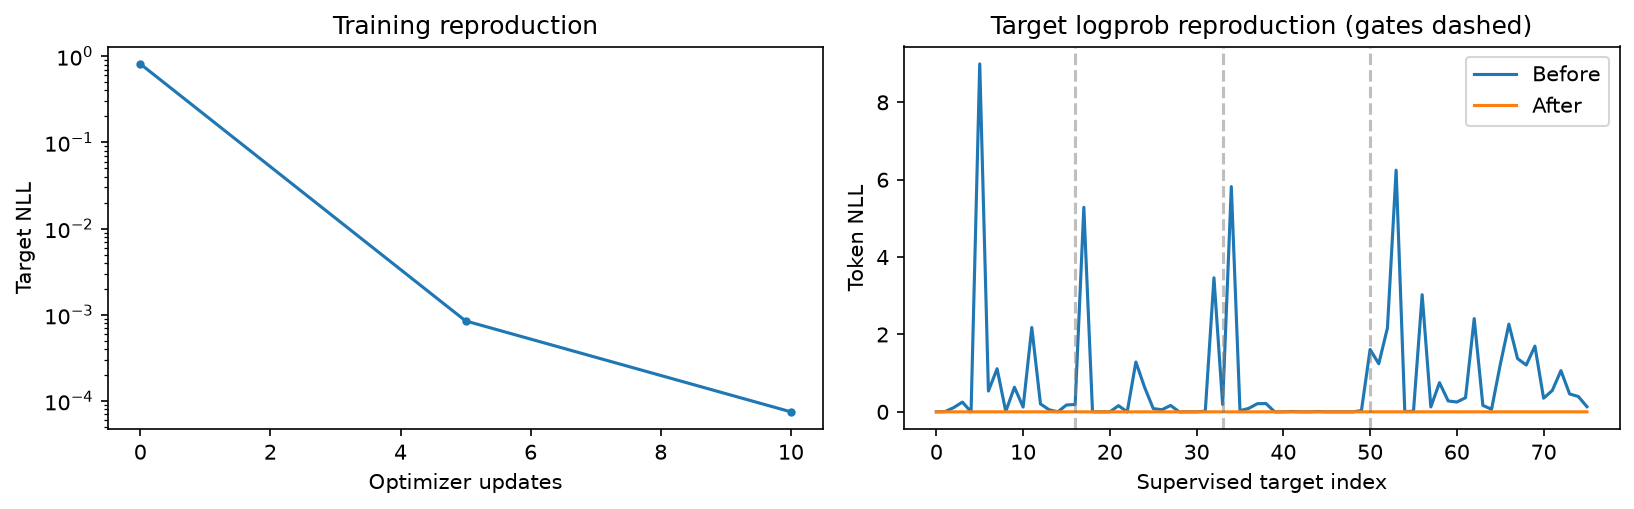

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(
    [r["step"] for r in training["history"]], [r["loss"] for r in training["history"]], marker="."
)
axes[0].set(
    xlabel="Optimizer updates", ylabel="Target NLL", title="Training reproduction", yscale="log"
)
axes[1].plot(training["initial"]["examples"][0]["nll"], label="Before")
axes[1].plot(training["final"]["examples"][0]["nll"], label="After")
for i, sample in enumerate(teacher["samples"]):
    if sample["role"] == "gate":
        axes[1].axvline(i, color="grey", linestyle="--", alpha=0.5)
axes[1].set(
    xlabel="Supervised target index",
    ylabel="Token NLL",
    title="Target logprob reproduction (gates dashed)",
)
axes[1].legend()
plt.tight_layout()
display_figure(fig)
plt.close(fig)


## G. Reloaded student: free generation and before/after

The checkpoint is loaded into the real AsyncLLM engine. It receives only the original prompt and the scheduled frames. It generates its own thinker tokens, gate actions and answer; there is no teacher-token or teacher-action injection.

In [9]:
checkpoint = RUN / "trained/checkpoint"
reload_path = RUN / "checkpoint_reload.json"
if not reload_path.exists():
    isolated(
        exp.verify_checkpoint,
        teacher_path,
        checkpoint,
        training_path,
        reload_path,
        log_path=RUN / "checkpoint_reload.log",
    )
print(
    "Reload retains training replay:",
    exp.require_replay_options(exp.load(reload_path), SETUP)["passed"],
)
after_path, after = collect_once(checkpoint, "student_after")
print("Student after:", after["assessment"])
print("Gate decisions:", after["gates"])
print("Thinker:", after["thinker_text"])
print("Writer:", after["answer_text"])


Reload retains training replay: True


Student after: {'reply_time': 12.0, 'in_reference_window': True, 'correct_gate_sequence': True, 'facts': {'smoke': True, 'building': True, 'explosion_or_fire': True}, 'answer_grounded': True, 'behavior_reproduced': True}
Gate decisions: [{'frame': 0, 'video_time': 2.0, 'reply': False, 'token': 2083, 'margin': -9.578125}, {'frame': 1, 'video_time': 5.0, 'reply': False, 'token': 2083, 'margin': -11.4375}, {'frame': 2, 'video_time': 12.0, 'reply': True, 'token': 9405, 'margin': 22.296875}]
Thinker: The user wants me to compare two video frames to identify any suspicious or harmful activities1.  **Analyze the first frame (2.0s):** The2.  **Analyze the second frame (12.0s):**
Writer: A large plume of dark smoke is rising from the center of the building's facade, indicating a fire or explosion.


### Visual control: freeze the stream before the event

Preserve the same timestamps, number of updates, prompts and decoding policies, but repeat the last pre-event frame instead of providing the event frames. The student should keep waiting and emit no answer. This tests whether it learned an event tied to the actual new pixels rather than a fixed frame index. The comparison verifies the processed pixel tensors, not only frame filenames.

In [10]:
freeze_path, freeze = collect_once(checkpoint, "student_freeze", control="freeze")
print("Frozen stream:", freeze["assessment"])
print("Gate decisions:", freeze["gates"])
print("Answer:", repr(freeze["answer_text"]))
comparison_path = RUN / "comparison.json"
if not comparison_path.exists():
    exp.compare(teacher_path, before_path, after_path, freeze_path, comparison_path)
comparison = exp.require_replay_options(exp.load(comparison_path), SETUP)
print(json.dumps(comparison, indent=2))


Frozen stream: {'correct_wait': True, 'behavior_reproduced': False, 'reply_time': None, 'facts': {'smoke': False, 'building': False, 'explosion_or_fire': False}}
Gate decisions: [{'frame': 0, 'video_time': 2.0, 'reply': False, 'token': 2083, 'margin': -9.578125}, {'frame': 1, 'video_time': 5.0, 'reply': False, 'token': 2083, 'margin': -11.4375}, {'frame': 2, 'video_time': 12.0, 'reply': False, 'token': 2083, 'margin': -11.671875}, {'frame': 3, 'video_time': 14.0, 'reply': False, 'token': 2083, 'margin': -12.109375}]
Answer: ''


{
  "replay_options": {
    "attention_backend": "torch",
    "query_chunk_size": 64
  },
  "runs": {
    "before": {
      "assessment": {
        "reply_time": null,
        "in_reference_window": false,
        "correct_gate_sequence": false,
        "facts": {
          "smoke": false,
          "building": false,
          "explosion_or_fire": false
        },
        "answer_grounded": false,
        "behavior_reproduced": false
      },
      "tokens": {
        "thinker": {
          "exact": false,
          "common_prefix": 5,
          "positional_agreement": 0.15625,
          "sequence_similarity": 0.35714285714285715
        },
        "writer": {
          "exact": false,
          "common_prefix": 0,
          "positional_agreement": 0.0,
          "sequence_similarity": 0.0
        }
      },
      "exact_gate_tokens": false,
      "same_events": false,
      "exact_trajectory": false,
      "reply_time": null,
      "answer": ""
    },
    "after": {
      "assessment

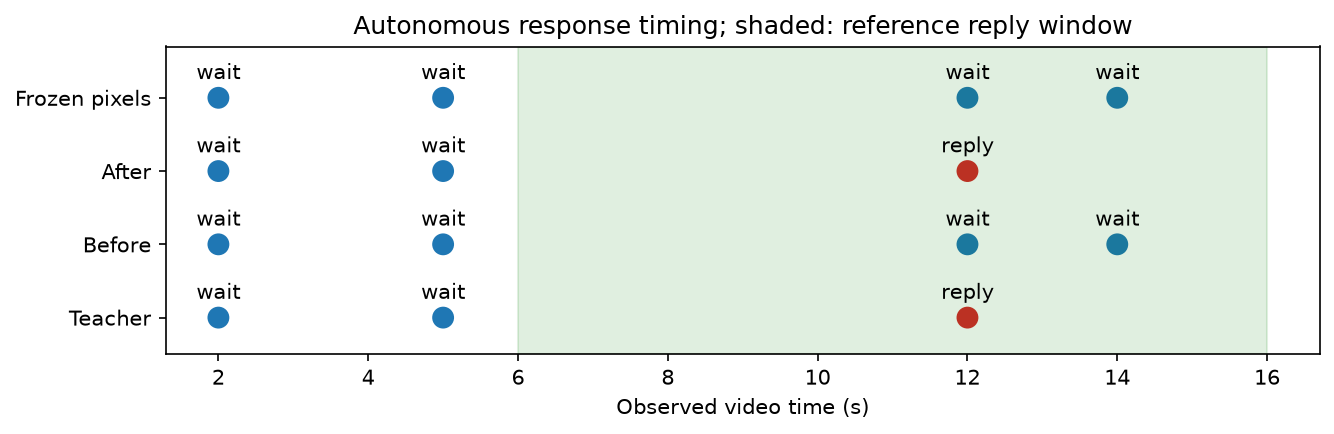

In [11]:
fig, ax = plt.subplots(figsize=(9, 3))
for y, (name, run) in enumerate(
    [("Teacher", teacher), ("Before", before), ("After", after), ("Frozen pixels", freeze)]
):
    times = [g["video_time"] for g in run["gates"]]
    colors = ["tab:red" if g["reply"] else "tab:blue" for g in run["gates"]]
    ax.scatter(times, [y] * len(times), c=colors, s=90)
    for g in run["gates"]:
        ax.annotate(
            "reply" if g["reply"] else "wait",
            (g["video_time"], y),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
        )
ax.axvspan(*task["annotation"]["answer"][0]["reply_timespan"], alpha=0.12, color="green")
ax.set(
    yticks=range(4),
    yticklabels=["Teacher", "Before", "After", "Frozen pixels"],
    xlabel="Observed video time (s)",
    title="Autonomous response timing; shaded: reference reply window",
)
ax.set_ylim(-0.5, 3.7)
plt.tight_layout()
display_figure(fig)
plt.close(fig)


Content checks are explicit and task-specific: smoke plus a building, independently reported fire/explosion language, reply inside the annotation window, correct gate sequence and EOS. Exact thinker/writer/gate tokens are a different metric. These checks are not a general semantic judge and do not compute the benchmark's full PAUC.

This diagnostic uses sparse frame pairs and one generating observer plus a decision/answer branch. It does not implement native temporal video tensors, audio, a complete SoccerNet evaluation or wall-clock frame dropping. Timing here is tied to observed video timestamps under a fixed token-count schedule.

In [12]:
print("Free-running behavioral reproduction:", comparison["free_running_success"])
print("Exact complete trajectory:", comparison["exact_trajectory"])
print("Frozen-pixel control:", comparison["visual_control_passed"])
if not (comparison["free_running_success"] and comparison["visual_control_passed"]):
    display(
        Markdown(
            "**Experiment incomplete.** Inspect gate timing, answer text and the visual control. Low teacher-forced loss does not establish success."
        )
    )
else:
    display(
        Markdown(
            "**Free-running video reproduction and visual control passed.** Exact token reproduction is reported separately above."
        )
    )
print("Artifacts:", RUN)


Free-running behavioral reproduction: True
Exact complete trajectory: True
Frozen-pixel control: True


**Free-running video reproduction and visual control passed.** Exact token reproduction is reported separately above.

Artifacts: /home/mrozaeva/experiments/video-replay-refresh-20261127/training_runs/executed_notebook
